# Task 1: Climate Indices (ONI + DMI)

**Project:** Kenya County Flood Risk Early Warning (Group 6)

**Goal:** build one clean monthly table of the two ocean climate drivers, **ONI** (El Niño / La Niña) and **DMI** (Indian Ocean Dipole), for January 2000 to December 2025 (312 months), then explore them.

| | |
|---|---|
| **Inputs (never edited)** | `data/raw/climate_indices/oni.csv`, `data/raw/climate_indices/dmi_ersstv6.txt` |
| **Output** | `data/processed/climate_indices_month.csv` (312 rows; columns `year, month, oni, dmi`) |

**Plan:** Part A cleans and merges the two files. Part B explores them with summary statistics and charts.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Paths are relative to this notebook (it lives in notebooks/)
RAW = Path("../data/raw/climate_indices")
OUT = Path("../data/processed")
FIGS = Path("figures")          # charts for the slides are saved here
OUT.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 20)

## Part A: Cleaning

### A1. Load ONI and inspect it

What we know from opening the file in a terminal:
- Line 1 is a header line containing a long text note, so we skip it and name the columns ourselves.
- Dates look like `1950-01-01` and the values have spaces in front of them (`skipinitialspace=True` handles this).
- Missing values are `-9999.000`. The header says `-99.9`, but that is wrong.

In [17]:
oni_raw = pd.read_csv(
    RAW / "oni.csv",
    skiprows=1,                 # skip the long header line
    names=["date", "oni"],
    skipinitialspace=True,
    parse_dates=["date"],
)

print("shape:", oni_raw.shape)
display(oni_raw.head(3))
display(oni_raw.tail(3))
print(oni_raw.dtypes)

n_missing_code = (oni_raw["oni"] == -9999).sum()
last_real = oni_raw.loc[oni_raw["oni"] != -9999, "date"].max()
print(f"\nrows coded -9999: {n_missing_code}")
print("last real ONI month:", last_real.strftime("%Y-%m"))

shape: (924, 2)


,date,oni
0,1950-01-01,-1.53
1,1950-02-01,-1.34
2,1950-03-01,-1.16


,date,oni
921,2026-10-01,-9999.0
922,2026-11-01,-9999.0
923,2026-12-01,-9999.0


date    datetime64[us]
oni            float64
dtype: object

rows coded -9999: 5
last real ONI month: 2026-07


### A2. Clean ONI

Turn `-9999` into `NaN`, split the date into `year` and `month`, and keep three columns: `year`, `month`, `oni`.

In [18]:
oni = oni_raw.copy()
oni["oni"] = oni["oni"].replace(-9999, np.nan)
oni["year"] = oni["date"].dt.year
oni["month"] = oni["date"].dt.month
oni = oni[["year", "month", "oni"]]

print("NaN after cleaning:", oni["oni"].isna().sum(), "(should equal the -9999 count above)")
display(oni.tail(8))

NaN after cleaning: 5 (should equal the -9999 count above)


,year,month,oni
916,2026,5,0.95
917,2026,6,1.39
918,2026,7,1.80
919,2026,8,NaN
920,2026,9,NaN
921,2026,10,NaN
922,2026,11,NaN
923,2026,12,NaN


### A3. Load DMI

`dmi_ersstv6.txt` is a text table, not a CSV. The first **12 lines** are notes (data sources, climatology, and the column header row), so we skip them and name the columns ourselves. Columns are separated by runs of spaces, hence `sep=r"\s+"`.

We only need `dmi`. WTIO and SETIO are the two parts it is calculated from (DMI = WTIO - SETIO), so we drop them.

`encoding="latin-1"` is there because the notes contain the degree symbol (º); the data lines are plain numbers either way.

In [19]:
dmi_raw = pd.read_csv(
    RAW / "dmi_ersstv6.txt",
    sep=r"\s+",
    skiprows=12,
    names=["year", "month", "wtio", "setio", "dmi"],
    encoding="latin-1",
)

print("shape:", dmi_raw.shape)
display(dmi_raw.head(3))
display(dmi_raw.tail(3))
print(dmi_raw.dtypes)
print("DMI min / max:", dmi_raw["dmi"].min(), "/", dmi_raw["dmi"].max())

shape: (920, 5)


,year,month,wtio,setio,dmi
0,1950,1,-0.76,-0.99,0.23
1,1950,2,-1.04,-0.63,-0.41
2,1950,3,-0.87,-0.40,-0.47


,year,month,wtio,setio,dmi
917,2026,6,0.39,0.53,-0.14
918,2026,7,0.68,0.39,0.29
919,2026,8,0.71,0.04,0.68


year       int64
month      int64
wtio     float64
setio    float64
dmi      float64
dtype: object
DMI min / max: -1.24 / 1.39


### A4. Clean DMI and check for a hidden missing-value code

The DMI min and max above should sit between about -3 and +3. If a value like -99.99 appeared, it would be a missing-value code, and the line below would turn it into `NaN`.

In [20]:
dmi = dmi_raw[["year", "month", "dmi"]].copy()

hidden_missing = (dmi["dmi"] < -90).sum()
dmi.loc[dmi["dmi"] < -90, "dmi"] = np.nan
print("hidden missing-value codes found in DMI:", hidden_missing)

hidden missing-value codes found in DMI: 0


### A5. Check both tables

For each table: duplicate months, gaps in the month sequence, NaN values, and values outside the normal range (about -3 to +3).

In [21]:
def check(df, col, name):
    p = pd.PeriodIndex(pd.to_datetime(dict(year=df["year"], month=df["month"], day=1)), freq="M")
    full = pd.period_range(p.min(), p.max(), freq="M")
    print(f"--- {name} ---")
    print("rows:", len(df), "| first:", p.min(), "| last:", p.max())
    print("duplicate months:", df.duplicated(["year", "month"]).sum())
    print("months missing from the sequence:", len(full.difference(p)))
    print("NaN values:", df[col].isna().sum())
    print("min / max:", df[col].min(), "/", df[col].max())
    print("values outside -3 to +3:", ((df[col] < -3) | (df[col] > 3)).sum())
    print()

check(oni, "oni", "ONI (all years)")
check(dmi, "dmi", "DMI (all years)")

--- ONI (all years) ---
rows: 924 | first: 1950-01 | last: 2026-12
duplicate months: 0
months missing from the sequence: 0
NaN values: 5
min / max: -2.03 / 2.75
values outside -3 to +3: 0

--- DMI (all years) ---
rows: 920 | first: 1950-01 | last: 2026-08
duplicate months: 0
months missing from the sequence: 0
NaN values: 0
min / max: -1.24 / 1.39
values outside -3 to +3: 0



**What the checks show**

- **Duplicates and gaps:** neither table has duplicate months or missing months (0 and 0 for both ONI and DMI).
- **Missing values:** ONI has 5 missing values (the -9999 codes). They are the months after the last real value, so none fall inside 2000 to 2025. DMI has no missing values.
- **Last real month:** ONI ends at July 2026 (1.80). DMI runs slightly further, to August 2026 (0.68).
- **Impossible values:** none. ONI sits between -2.03 and 2.75 and DMI between -1.24 and 1.39, all inside the usual -3 to +3 range.

### A6. Keep January 2000 to December 2025 and merge

Our modelling table covers 2000 to 2025, so we keep only those years from each table and merge on `year` + `month`. That should give exactly **312 rows** (26 years x 12 months).

In [22]:
oni_00_25 = oni[oni["year"].between(2000, 2025)]
dmi_00_25 = dmi[dmi["year"].between(2000, 2025)]
print("ONI rows:", len(oni_00_25), "| DMI rows:", len(dmi_00_25))

clim = oni_00_25.merge(dmi_00_25, on=["year", "month"], how="inner", validate="one_to_one")
clim = clim.sort_values(["year", "month"]).reset_index(drop=True)

print("merged shape:", clim.shape)
assert clim.shape == (312, 4), f"expected (312, 4) but got {clim.shape}"
display(clim.head(3))
display(clim.tail(3))

ONI rows: 312 | DMI rows: 312
merged shape: (312, 4)


,year,month,oni,dmi
0,2000,1,-1.66,-0.10
1,2000,2,-1.41,0.25
2,2000,3,-1.07,0.51


,year,month,oni,dmi
309,2025,10,-0.57,-0.56
310,2025,11,-0.61,-0.45
311,2025,12,-0.60,-0.39


### A7. Confirm there are no missing values left

In [23]:
print(clim.isna().sum())

rows_with_nan = clim[clim.isna().any(axis=1)]
if rows_with_nan.empty:
    print("\nNo missing values in 2000-2025.")
else:
    print("\nMonths with missing values (write these down):")
    display(rows_with_nan)

year     0
month    0
oni      0
dmi      0
dtype: int64

No missing values in 2000-2025.


## Part B: Exploring the data

### B1. Summary statistics

In [24]:
clim[["oni", "dmi"]].describe().round(2)

,oni,dmi
count,312.00,312.00
mean,-0.01,0.02
std,0.81,0.35
min,-1.66,-0.89
25%,-0.57,-0.20
50%,-0.13,-0.00
75%,0.46,0.22
max,2.75,1.17


### B2. Line chart: ONI and DMI, 2000 to 2025

The dashed lines at **+0.5 and -0.5** are the usual thresholds for El Niño (ONI at or above +0.5) and La Niña (ONI at or below -0.5).

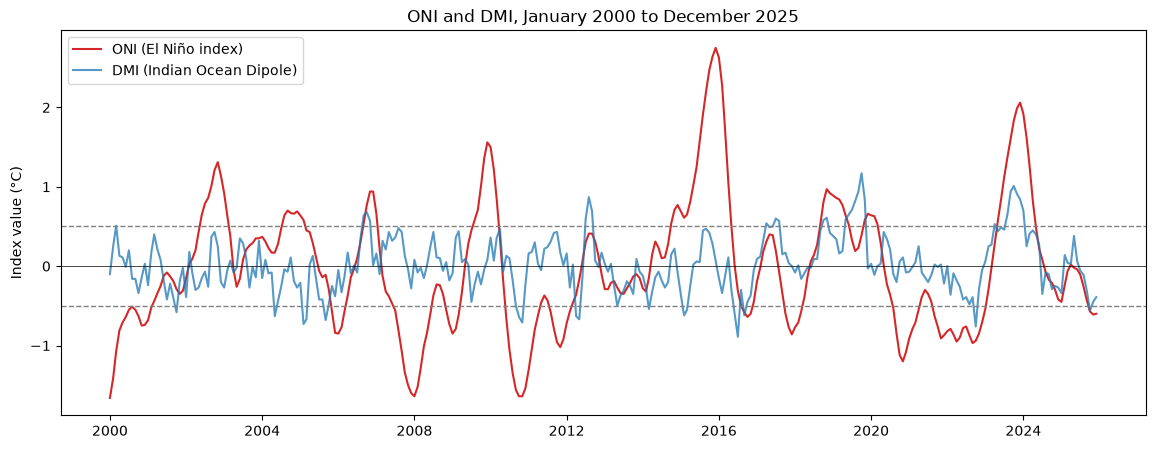

In [25]:
clim["date"] = pd.to_datetime(dict(year=clim["year"], month=clim["month"], day=1))

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(clim["date"], clim["oni"], label="ONI (El Niño index)", color="tab:red")
ax.plot(clim["date"], clim["dmi"], label="DMI (Indian Ocean Dipole)", color="tab:blue", alpha=0.75)
for y in (0.5, -0.5):
    ax.axhline(y, ls="--", color="grey", lw=1)
ax.axhline(0, color="black", lw=0.5)
ax.set_title("ONI and DMI, January 2000 to December 2025")
ax.set_ylabel("Index value (°C)")
ax.legend(loc="upper left")
fig.savefig(FIGS / "fig1_oni_dmi.png", dpi=150, bbox_inches="tight")
plt.show()

### B3. Label the El Niño and positive IOD episodes

- **El Niño episode:** ONI at or above +0.5 for **5 or more months in a row**.
- **Positive IOD episode:** DMI at or above +0.4 for **3 or more months in a row** (DMI changes faster than ONI, so a shorter run is used).

These are simplified rules for exploration, not the official NOAA definitions. The helper below finds runs of consecutive months that meet a rule.

In [26]:
def find_runs(flag, min_len):
    """Return (start, end) positions of runs of True lasting at least min_len months."""
    runs, start = [], None
    for i, v in enumerate(flag.to_numpy()):
        if v and start is None:
            start = i
        if (not v) and start is not None:
            if i - start >= min_len:
                runs.append((start, i - 1))
            start = None
    if start is not None and len(flag) - start >= min_len:
        runs.append((start, len(flag) - 1))
    return runs

def episodes_table(col, threshold, min_len):
    runs = find_runs(clim[col] >= threshold, min_len)
    rows = [{
        "start": clim["date"].iloc[s].strftime("%Y-%m"),
        "end": clim["date"].iloc[e].strftime("%Y-%m"),
        "months": e - s + 1,
        "peak": round(clim[col].iloc[s:e + 1].max(), 2),
    } for s, e in runs]
    return pd.DataFrame(rows), runs

nino_tbl, nino_runs = episodes_table("oni", 0.5, 5)
iod_tbl, iod_runs = episodes_table("dmi", 0.4, 3)

print("El Niño episodes (ONI >= 0.5 for 5+ months):")
display(nino_tbl)
print("Positive IOD episodes (DMI >= 0.4 for 3+ months):")
display(iod_tbl)

El Niño episodes (ONI >= 0.5 for 5+ months):


,start,end,months,peak
0,2002-06,2003-02,9,1.31
1,2004-08,2005-02,7,0.70
2,2006-09,2007-01,5,0.94
3,2009-08,2010-03,8,1.56
4,2014-10,2016-04,19,2.75
5,2018-09,2019-06,10,0.97
6,2019-11,2020-03,5,0.66
7,2023-05,2024-04,12,2.06


Positive IOD episodes (DMI >= 0.4 for 3+ months):


,start,end,months,peak
0,2006-09,2006-11,3,0.68
1,2012-07,2012-09,3,0.87
2,2015-08,2015-10,3,0.47
3,2017-04,2017-08,5,0.60
4,2018-09,2018-12,4,0.61
5,2019-05,2019-11,7,1.17
6,2023-04,2024-01,10,1.01
7,2024-03,2024-05,3,0.45


**Check against the task sheet's years**

All the years the task sheet suggested show up in the tables above.

- **El Niño:** 2006 (Sep 2006 to Jan 2007, peak 0.94), 2009 (Aug 2009 to Mar 2010, peak 1.56), 2015 (Oct 2014 to Apr 2016, peak 2.75) and 2023 (May 2023 to Apr 2024, peak 2.06).
- **Positive IOD:** 2006 (Sep to Nov 2006, peak 0.68), 2019 (May to Nov 2019, peak 1.17) and 2023 (Apr 2023 to Jan 2024, peak 1.01).
- **Extra episodes the rules also pick up:** El Niño in 2002, 2004, 2018 and 2019-20, and positive IOD in 2012, 2015, 2017, 2018 and 2024.
- **Borderline cases:** the 2006 El Niño lasts exactly 5 months and the 2006 IOD exactly 3 months, so they only just pass my cut-offs. The 2015 El Niño starts in late 2014, so it is labelled 2014 on the chart.

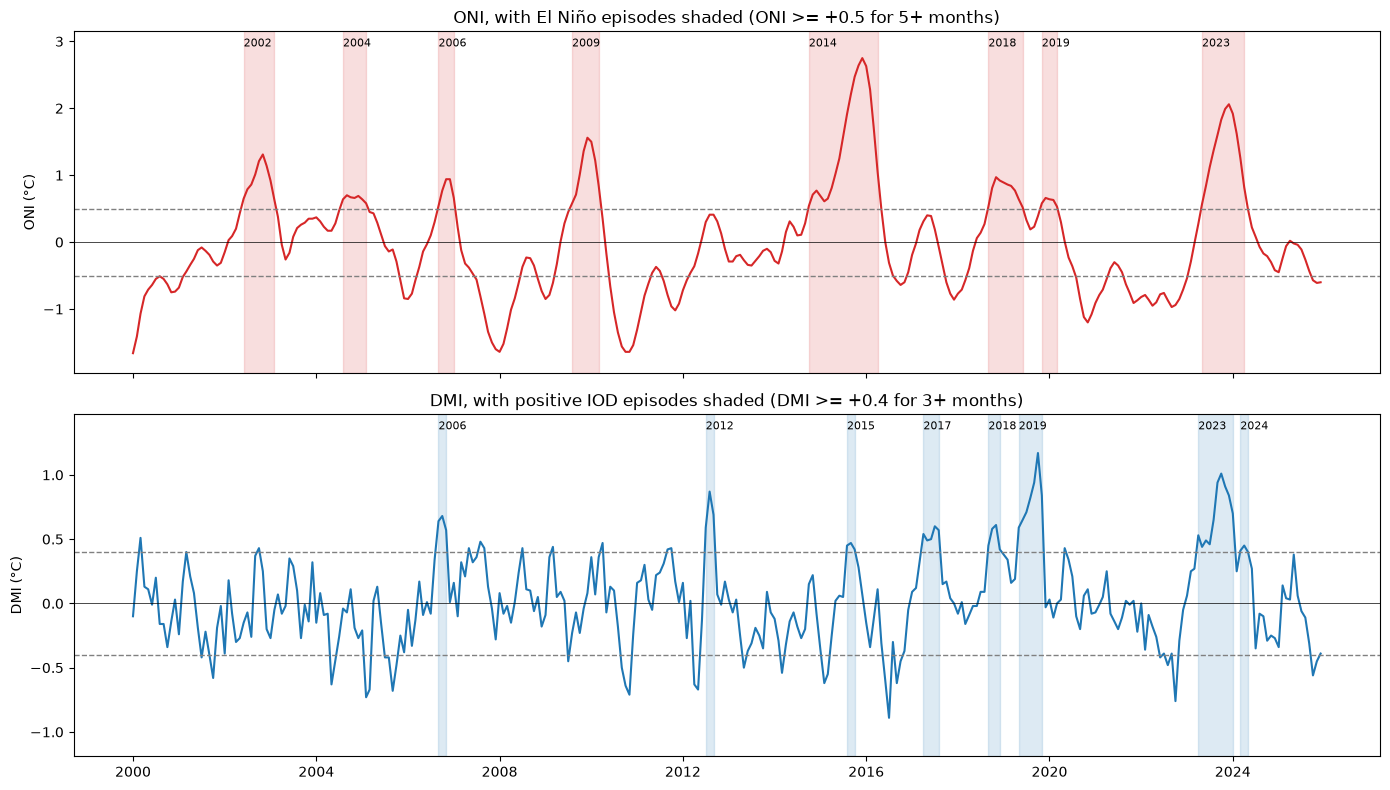

In [27]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Top panel: ONI with El Niño episodes shaded
ax1.plot(clim["date"], clim["oni"], color="tab:red")
for y in (0.5, -0.5):
    ax1.axhline(y, ls="--", color="grey", lw=1)
ax1.axhline(0, color="black", lw=0.5)
ymax = clim["oni"].max() + 0.4
ax1.set_ylim(clim["oni"].min() - 0.3, ymax)
for s, e in nino_runs:
    ax1.axvspan(clim["date"].iloc[s], clim["date"].iloc[e], color="tab:red", alpha=0.15)
    ax1.text(clim["date"].iloc[s], ymax - 0.1, str(clim["date"].iloc[s].year), fontsize=8, va="top")
ax1.set_title("ONI, with El Niño episodes shaded (ONI >= +0.5 for 5+ months)")
ax1.set_ylabel("ONI (°C)")

# Bottom panel: DMI with positive IOD episodes shaded
ax2.plot(clim["date"], clim["dmi"], color="tab:blue")
for y in (0.4, -0.4):
    ax2.axhline(y, ls="--", color="grey", lw=1)
ax2.axhline(0, color="black", lw=0.5)
ymax2 = clim["dmi"].max() + 0.3
ax2.set_ylim(clim["dmi"].min() - 0.3, ymax2)
for s, e in iod_runs:
    ax2.axvspan(clim["date"].iloc[s], clim["date"].iloc[e], color="tab:blue", alpha=0.15)
    ax2.text(clim["date"].iloc[s], ymax2 - 0.05, str(clim["date"].iloc[s].year), fontsize=8, va="top")
ax2.set_title("DMI, with positive IOD episodes shaded (DMI >= +0.4 for 3+ months)")
ax2.set_ylabel("DMI (°C)")

fig.tight_layout()
fig.savefig(FIGS / "fig2_episodes.png", dpi=150, bbox_inches="tight")
plt.show()

### B4. Bar chart: El Niño, La Niña and neutral months per year

Each month is labelled by its ONI value: El Niño (>= +0.5), La Niña (<= -0.5), otherwise neutral. This is a simple month-by-month rule, so it will count slightly differently from NOAA's official episodes, which need several overlapping seasons in a row.

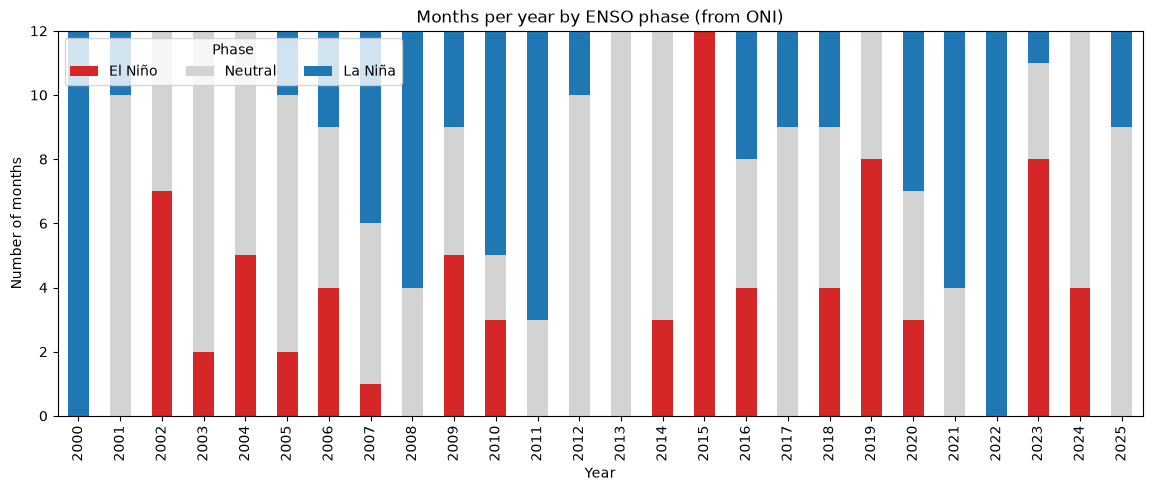

Total months: {'El Niño': 75, 'Neutral': 144, 'La Niña': 93}


In [28]:
clim["phase"] = np.select(
    [clim["oni"] >= 0.5, clim["oni"] <= -0.5],
    ["El Niño", "La Niña"],
    default="Neutral",
)

order = ["El Niño", "Neutral", "La Niña"]
counts = (clim.groupby(["year", "phase"]).size()
              .unstack(fill_value=0)
              .reindex(columns=order, fill_value=0))

ax = counts.plot(kind="bar", stacked=True, figsize=(14, 5),
                 color=["tab:red", "lightgrey", "tab:blue"])
ax.set_title("Months per year by ENSO phase (from ONI)")
ax.set_xlabel("Year")
ax.set_ylabel("Number of months")
ax.legend(title="Phase", loc="upper left", ncol=3)
plt.savefig(FIGS / "fig3_phase_counts.png", dpi=150, bbox_inches="tight")
plt.show()

print("Total months:", counts.sum().to_dict())

### B5. Do El Niño and positive IOD happen together?

The numbers below measure how often the two overlap. They back up the findings in B6.

In [29]:
print("Correlation between ONI and DMI (same month):")
display(clim[["oni", "dmi"]].corr().round(2))

nino_m = clim["oni"] >= 0.5
iod_m = clim["dmi"] >= 0.4
both = (nino_m & iod_m).sum()

print(f"El Niño months (ONI >= 0.5):          {nino_m.sum()}")
print(f"Positive IOD months (DMI >= 0.4):     {iod_m.sum()}")
print(f"Months with both at the same time:    {both}")
print(f"Share of El Niño months that also had a positive IOD: {both / nino_m.sum():.0%}")
print(f"Share of positive-IOD months that also had El Niño:  {both / iod_m.sum():.0%}")

print("\nStrongest values:")
for col in ["oni", "dmi"]:
    r = clim.loc[clim[col].idxmax()]
    print(f"Highest {col.upper()}: {r[col]:.2f} in {int(r['year'])}-{int(r['month']):02d}")

Correlation between ONI and DMI (same month):


,oni,dmi
oni,1.00,0.32
dmi,0.32,1.00


El Niño months (ONI >= 0.5):          75
Positive IOD months (DMI >= 0.4):     50
Months with both at the same time:    25
Share of El Niño months that also had a positive IOD: 33%
Share of positive-IOD months that also had El Niño:  50%

Strongest values:
Highest ONI: 2.75 in 2015-12
Highest DMI: 1.17 in 2019-10


### B6. Findings

Between 2000 and 2025 the rules pick out 8 El Niño episodes and 8 positive IOD episodes. The strongest El Niños were 2015-16 (ONI peaked at 2.75 in December 2015, over 19 months) and 2023-24 (peak 2.06), and the strongest positive IODs were 2019 (DMI peak 1.17 in October) and 2023 (peak 1.01). El Niño and positive IOD overlap only partly: the correlation between ONI and DMI is 0.32, and just 25 of the 312 months have both, which is 33% of El Niño months and 50% of positive IOD months. 2023 is the clearest year with both at once; 2019 had a strong positive IOD without a strong El Niño, and 2015 had a very strong El Niño with only a brief, weak IOD (peak 0.47). Neutral months are the most common (144 of 312), followed by La Niña (93) and El Niño (75), so for our model ONI and DMI should go in as two separate features rather than one standing in for the other. The episode rules here are simple cut-offs I chose, not the official NOAA definitions, and this notebook describes the climate drivers only, it does not show that any of these episodes caused floods.

## Save the cleaned table

One row per month, 312 rows, columns `year, month, oni, dmi`. The raw files are not touched.

In [30]:
final = clim[["year", "month", "oni", "dmi"]]
final.to_csv(OUT / "climate_indices_month.csv", index=False)

# Re-read the saved file to confirm it is what we expect
check_df = pd.read_csv(OUT / "climate_indices_month.csv")
print("saved shape:", check_df.shape)
print("columns:", list(check_df.columns))
print("missing values:", int(check_df.isna().sum().sum()))
assert check_df.shape == (312, 4)
assert list(check_df.columns) == ["year", "month", "oni", "dmi"]
display(check_df.head())

saved shape: (312, 4)
columns: ['year', 'month', 'oni', 'dmi']
missing values: 0


,year,month,oni,dmi
0,2000,1,-1.66,-0.10
1,2000,2,-1.41,0.25
2,2000,3,-1.07,0.51
3,2000,4,-0.81,0.13
4,2000,5,-0.71,0.11
